#### Deep models - LSTM, GRU, CNN-LSTM, attention

Input = sliding window of the last L hours (scaled load + calendar features), target = load h hours after the last input hour.
The calendar of the target hour (hour, month, weekday, weekend, holiday) is known in advance, so it is also given to the
models (added just before the output layer). The tree models get the same information.

The setup is kept small so the whole notebook runs in a few hours. The tree models in notebook 04 use the same setup:
- each model is tuned once per dataset at h=24 (8 Optuna trials, 4 epochs each), best settings reused for 1h and 168h
- window length L from 24, 48 or 72 hours (168 was too slow). For h=168 the last input hour is
  still the same hour one week before the target
- PJME: trained on the last 4 years of the train period (~35k hours, similar size to UCI train). val / test are the full periods
- final models: 3 seeds, max 10 epochs with early stopping on val

In [1]:
import os
import json
import time
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import optuna
# tensorflow / keras = the library used to build and train the neural networks
import tensorflow as tf
import keras
from keras import layers
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score

# show fewer log messages
optuna.logging.set_verbosity(optuna.logging.WARNING)
tf.get_logger().setLevel("ERROR")
tf.autograph.set_verbosity(0)

os.makedirs("../figures", exist_ok=True)

In [2]:
# why: same horizons, seeds and number of tuning trials as the tree models in notebook 04, so the comparison is fair
HORIZONS = [1, 24, 168]
SEEDS = [0, 1, 2]
N_TRIALS = 8
# epoch = one full pass over the training data. 4 epochs while tuning, up to 10 for the final models
TUNE_EPOCHS = 4
MAX_EPOCHS = 10
# batch = how many samples the network sees before it updates its weights
BATCH = 512
PJME_TRAIN_HOURS = 24 * 365 * 4

# FEATURES = columns inside the input window. TARGET_FEATURES = calendar of the hour we predict
# (it is known in advance, e.g. we know that next Monday is a holiday)
FEATURES = ["load", "hour_sin", "hour_cos", "month_sin", "month_cos", "dayofweek", "weekend", "holiday"]
TARGET_FEATURES = ["hour_sin", "hour_cos", "month_sin", "month_cos", "dayofweek", "weekend", "holiday"]
MODELS = ["lstm", "gru", "cnn_lstm", "attention"]

os.makedirs("../results/predictions", exist_ok=True)

##### Data and windows

Windows are not stored, they are cut out with tf.gather for each batch (saves memory).
The val / test windows can look back into the previous split, same as the tree features.

In [3]:
# load_data: reads the scaled data (input for the networks) and the real data (to score in MW / kW)
# and puts everything in one dictionary
def load_data(name):
    parts = [pd.read_parquet(f"../data/processed/{name}_{p}_scaled.parquet") for p in ["train", "val", "test"]]
    raw = [pd.read_parquet(f"../data/processed/{name}_{p}.parquet") for p in ["train", "val", "test"]]
    # join train + val + test into one long table, in time order
    full = pd.concat(parts)
    actual = pd.concat(raw)["load"]
    n_tr, n_va = len(parts[0]), len(parts[1])

    # joblib.load() reads the scaler saved in notebook 02
    scaler = joblib.load(f"../data/processed/{name}_scaler.pkl")
    # min and range of the load column, needed to change predictions back from 0-1 to MW / kW
    lo, rng = scaler.data_min_[0], scaler.data_range_[0]   # load is the first column

    return {
        # tf.constant() changes the numpy arrays into tensors, the data type tensorflow works with
        "X": tf.constant(full[FEATURES].values, dtype=tf.float32),
        "C": tf.constant(full[TARGET_FEATURES].values, dtype=tf.float32),
        "y": tf.constant(full["load"].values, dtype=tf.float32),
        "index": full.index,
        "actual": actual.values,
        "n_tr": n_tr, "n_va": n_va, "n": len(full),
        "lo": lo, "rng": rng,
    }


# target_rows: gives the row numbers of the hours we want to predict in one part (train, val or test)
def target_rows(d, name, part, L, h):
    if part == "train":
        # the first target needs L hours of history that end h hours before it, so we can't start at row 0
        start = L - 1 + h
        if name == "pjme":
            # for PJME only the last 4 years of train are used (same as the tree models)
            start = max(start, d["n_tr"] - PJME_TRAIN_HOURS)
        # np.arange(a, b) = the numbers a, a+1, ..., b-1
        return np.arange(start, d["n_tr"])
    if part == "val":
        return np.arange(d["n_tr"], d["n_tr"] + d["n_va"])
    return np.arange(d["n_tr"] + d["n_va"], d["n"])


# make_ds: makes the batches for keras. for each target hour t it cuts out a window of L hours
# that ends h hours before t.
# e.g. L = 48, h = 24: to predict hour 100 the window is hours 29 to 76
def make_ds(d, rows, L, h, shuffle=False, seed=0, window_only=False):
    # offsets = the positions of the window compared to the target hour
    offsets = tf.range(-h - L + 1, -h + 1, dtype=tf.int64)

    # get_batch: takes a batch of target rows and gives back (window, calendar), target
    def get_batch(t):
        # tf.gather() picks rows by their number. t + offsets = all row numbers of each window
        x = tf.gather(d["X"], t[:, None] + offsets[None, :])
        if window_only:
            return x
        c = tf.gather(d["C"], t)      # calendar of the target hour
        y = tf.gather(d["y"], t)
        return (x, c), y

    # from_tensor_slices() makes a dataset from the list of target rows
    ds = tf.data.Dataset.from_tensor_slices(rows.astype("int64"))
    if shuffle:
        # shuffle the training samples so the batches are mixed
        ds = ds.shuffle(len(rows), seed=seed)
    # batch() makes groups of 512, map() cuts the windows, prefetch() prepares the next batch while training
    return ds.batch(BATCH).map(get_batch).prefetch(tf.data.AUTOTUNE)

In [4]:
# small test: one batch for PJME with a 48 hour window, 24 hours ahead
d = load_data("pjme")
(x, c), y = next(iter(make_ds(d, target_rows(d, "pjme", "train", 48, 24), 48, 24)))
# x = (batch, window length, features), c = (batch, calendar features), y = (batch,)
print(x.shape, c.shape, y.shape)
print("train targets:", len(target_rows(d, "pjme", "train", 48, 24)),
      "val:", len(target_rows(d, "pjme", "val", 48, 24)),
      "test:", len(target_rows(d, "pjme", "test", 48, 24)))

(512, 48, 8) (512, 7) (512,)
train targets: 35040 val: 21809 test: 21809


##### Models

Attention model is a simplified Temporal Fusion Transformer: LSTM encoder, gated residual connections
and multi-head attention where the query is the last time step. The attention scores show how much each
past hour is used.

All four models end with the same small head: the output of the network is joined with the calendar of
the target hour, then one dense layer and the output.

In [5]:
# gate_add_norm: a small block taken from the TFT paper. the gate decides how much of the new
# information is kept, then the old input (skip) is added back and the result is normalised
def gate_add_norm(x, skip, units):
    # GLU gate + residual + layer norm (from TFT)
    g = layers.Multiply()([layers.Dense(units)(x), layers.Dense(units, activation="sigmoid")(x)])
    return layers.LayerNormalization()(layers.Add()([g, skip]))


# head: the last part of every model. joins the network output with the calendar of the target hour
# and gives one number = the predicted load (still scaled 0-1)
def head(x, cal):
    # join with the calendar of the target hour, then the output
    z = layers.Concatenate()([x, cal])
    z = layers.Dense(32, activation="relu")(z)
    return layers.Dense(1)(z)


# build_model: builds one of the four networks (lstm, gru, cnn_lstm or attention).
# p = the settings (units, dropout, ...), L = window length.
# why: these are the four deep models compared in the project
def build_model(kind, p, L):
    # two inputs: the window of past hours and the calendar of the target hour
    inp = keras.Input((L, len(FEATURES)))
    cal = keras.Input((len(TARGET_FEATURES),))

    if kind in ["lstm", "gru"]:
        # LSTM and GRU are built the same way, only the layer type is different
        rnn = layers.LSTM if kind == "lstm" else layers.GRU
        x = inp
        for i in range(p["layers"]):
            # return_sequences=True gives the output of every hour to the next layer. the last layer gives only the final output
            x = rnn(p["units"], return_sequences=i < p["layers"] - 1)(x)
            # Dropout switches off some units at random during training, which helps against overfitting
            x = layers.Dropout(p["dropout"])(x)
        out = head(x, cal)
        att = None

    elif kind == "cnn_lstm":
        # Conv1D slides a small filter over the window to find short patterns (e.g. a morning rise).
        # padding="causal" = the filter only looks at earlier hours
        x = layers.Conv1D(p["filters"], p["kernel"], padding="causal", activation="relu")(inp)
        # MaxPooling1D(2) keeps the bigger of every 2 values, so the sequence becomes half as long
        x = layers.MaxPooling1D(2)(x)
        # the LSTM then reads the shorter sequence
        x = layers.LSTM(p["units"])(x)
        x = layers.Dropout(p["dropout"])(x)
        out = head(x, cal)
        att = None

    else:
        u = p["units"]
        # Dense(u) changes the 8 input features into u numbers for every hour
        emb = layers.Dense(u)(inp)
        enc = layers.LSTM(u, return_sequences=True)(emb)
        enc = gate_add_norm(layers.Dropout(p["dropout"])(enc), emb, u)

        # query = the last hour of the window. attention asks: which earlier hours matter for this one?
        query = enc[:, -1:, :]
        # MultiHeadAttention gives back the result and also the weights (att), one weight per past hour
        a, att = layers.MultiHeadAttention(num_heads=p["heads"], key_dim=u // p["heads"], dropout=p["dropout"])(
            query, enc, return_attention_scores=True)
        x = gate_add_norm(layers.Dropout(p["dropout"])(a), query, u)

        # position-wise feed forward (GRN)
        f = layers.Dense(u, activation="elu")(x)
        f = layers.Dense(u)(f)
        x = gate_add_norm(f, x, u)
        out = head(layers.Flatten()(x), cal)

    # keras.Model joins inputs and output into one model
    model = keras.Model([inp, cal], out)
    # Adam = the optimiser that updates the weights, lr = learning rate (step size), mse = mean squared error loss
    model.compile(optimizer=keras.optimizers.Adam(p["lr"]), loss="mse")
    # second small model that only gives the attention weights, used for the plots later
    att_model = keras.Model(inp, att) if att is not None else None
    return model, att_model

In [6]:
# suggest: the search space for optuna. gives back one set of settings to try for a model type
def suggest(trial, kind):
    p = {
        # suggest_categorical picks one value from a list, e.g. window length 24, 48 or 72 hours
        "L": trial.suggest_categorical("L", [24, 48, 72]),
        "lr": trial.suggest_float("lr", 1e-4, 1e-2, log=True),
        "dropout": trial.suggest_float("dropout", 0.0, 0.3),
        "units": trial.suggest_categorical("units", [32, 64, 128]),
    }
    if kind in ["lstm", "gru"]:
        p["layers"] = trial.suggest_int("layers", 1, 2)
    if kind == "cnn_lstm":
        p["filters"] = trial.suggest_categorical("filters", [32, 64])
        p["kernel"] = trial.suggest_categorical("kernel", [3, 5])
    if kind == "attention":
        p["heads"] = trial.suggest_categorical("heads", [2, 4])
    return p


# train: builds and trains one model. gives back the model, the best val loss and the number of epochs used
def train(d, name, kind, p, h, epochs, seed):
    # set the random seed so the run can be repeated
    keras.utils.set_random_seed(seed)
    L = p["L"]
    model, att_model = build_model(kind, p, L)
    tr = make_ds(d, target_rows(d, name, "train", L, h), L, h, shuffle=True, seed=seed)
    va = make_ds(d, target_rows(d, name, "val", L, h), L, h)
    # EarlyStopping: stop if val loss has not improved for 2 epochs, and go back to the best weights
    stop = keras.callbacks.EarlyStopping(patience=2, restore_best_weights=True)
    # fit() trains the network. verbose=0 = no progress bar
    hist = model.fit(tr, validation_data=va, epochs=epochs, callbacks=[stop], verbose=0)
    return model, att_model, min(hist.history["val_loss"]), len(hist.history["loss"])


# predict: makes the forecasts for one part (test by default) and changes them back to MW / kW
def predict(d, name, model, L, h, part="test"):
    rows = target_rows(d, name, part, L, h)
    # ravel() makes the output a flat list, e.g. [[1], [2]] -> [1, 2]
    pred = model.predict(make_ds(d, rows, L, h), verbose=0).ravel()
    # undo the 0-1 scaling: value * (max - min) + min
    return rows, pred * d["rng"] + d["lo"]


# scores: the same four error measures as in notebook 04
def scores(y, pred):
    return {
        "rmse": np.sqrt(mean_squared_error(y, pred)),
        "mae": mean_absolute_error(y, pred),
        "mape": mean_absolute_percentage_error(y, pred) * 100,
        "r2": r2_score(y, pred),
    }

##### Tuning (h=24)

In [7]:
# why: every deep model gets the same small search (8 trials at h = 24) as the tree models.
# the best settings are saved and reused for all horizons
best_params = {}
t0 = time.time()

for name in ["pjme", "uci"]:
    d = load_data(name)
    best_params[name] = {}
    for kind in MODELS:
        start = time.time()

        # objective: optuna calls this for every trial. it trains one model and gives back the val loss (lower is better)
        def objective(trial):
            p = suggest(trial, kind)
            _, _, val_loss, _ = train(d, name, kind, p, 24, TUNE_EPOCHS, seed=0)
            return val_loss

        study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
        study.optimize(objective, n_trials=N_TRIALS)
        best_params[name][kind] = study.best_params
        print(f"{name} {kind}: {study.best_params}  ({time.time() - start:.0f}s)")

print(f"tuning took {(time.time() - t0) / 60:.1f} min")

# save the best settings as a json file
with open("../results/deep_params.json", "w") as f:
    json.dump(best_params, f, indent=2)

pjme lstm: {'L': 72, 'lr': 0.0007591104805282694, 'dropout': 0.036611470453433645, 'units': 128, 'layers': 1}  (523s)


pjme gru: {'L': 72, 'lr': 0.0007591104805282694, 'dropout': 0.036611470453433645, 'units': 128, 'layers': 1}  (556s)


pjme cnn_lstm: {'L': 48, 'lr': 0.0015751320499779737, 'dropout': 0.04680559213273095, 'units': 128, 'filters': 64, 'kernel': 5}  (180s)


pjme attention: {'L': 48, 'lr': 0.00026587543983272726, 'dropout': 0.05454749016213018, 'units': 128, 'heads': 2}  (321s)


uci lstm: {'L': 48, 'lr': 0.0016409286730647919, 'dropout': 0.051157237106187456, 'units': 128, 'layers': 2}  (308s)


uci gru: {'L': 72, 'lr': 0.004622589001020831, 'dropout': 0.06370173320348284, 'units': 128, 'layers': 2}  (336s)


uci cnn_lstm: {'L': 72, 'lr': 0.0035503048581283078, 'dropout': 0.28184968246925673, 'units': 128, 'filters': 64, 'kernel': 5}  (117s)


uci attention: {'L': 48, 'lr': 0.006586289317583112, 'dropout': 0.07763399448000508, 'units': 32, 'heads': 2}  (193s)
tuning took 42.2 min


##### Final models - 3 horizons x 3 seeds

In [8]:
# why: this is the main training loop. every model is trained for 3 horizons x 3 seeds
# and the test predictions are saved for the evaluation in notebook 06
all_scores = []
attention = {}
t0 = time.time()

for name in ["pjme", "uci"]:
    d = load_data(name)
    for kind in MODELS:
        p = best_params[name][kind]
        for h in HORIZONS:
            start = time.time()
            preds = {}
            for seed in SEEDS:
                model, att_model, _, n_ep = train(d, name, kind, p, h, MAX_EPOCHS, seed)
                rows, pred = predict(d, name, model, p["L"], h)
                preds[f"seed_{seed}"] = pred

                if att_model is not None and seed == 0:
                    # mean attention over the test windows -> one weight per past hour
                    rows_te = target_rows(d, name, "test", p["L"], h)
                    a = att_model.predict(make_ds(d, rows_te, p["L"], h, window_only=True), verbose=0)
                    # a has one weight per (sample, head, query, past hour). mean over the first three -> one weight per past hour
                    attention[f"{name}_h{h}"] = a.mean(axis=(0, 1, 2))

            # real load (not scaled) for the same rows
            y_true = d["actual"][rows]
            out = pd.DataFrame(preds, index=d["index"][rows])
            out.insert(0, "actual", y_true)
            # save the predictions of the 3 seeds next to the actual values
            out.to_parquet(f"../results/predictions/{name}_{kind}_h{h}.parquet")
            for s, pred in preds.items():
                all_scores.append({"dataset": name, "model": kind, "horizon": h, "seed": s, **scores(y_true, pred)})

            print(f"{name} {kind} h={h}: test rmse {np.mean([scores(y_true, v)['rmse'] for v in preds.values()]):.3f}"
                  f"  ({time.time() - start:.0f}s)")

print(f"final training took {(time.time() - t0) / 60:.1f} min")

pjme lstm h=1: test rmse 1124.819  (375s)


pjme lstm h=24: test rmse 2580.774  (380s)


pjme lstm h=168: test rmse 3747.253  (204s)


pjme gru h=1: test rmse 829.096  (393s)


pjme gru h=24: test rmse 2509.028  (391s)


pjme gru h=168: test rmse 3748.276  (350s)


... (14 outputs left out)

uci cnn_lstm h=168: test rmse 0.599  (97s)


uci attention h=1: test rmse 0.514  (68s)


uci attention h=24: test rmse 0.607  (75s)


uci attention h=168: test rmse 0.613  (74s)
final training took 105.7 min


In [9]:
scores_df = pd.DataFrame(all_scores)
# save the scores of all deep models
scores_df.to_csv("../results/deep_scores.csv", index=False)

# attention weights: position 0 = oldest hour in the window, last = forecast origin
for k, w in attention.items():
    # [::-1] turns the list around, so 0 = the newest hour in the window
    pd.DataFrame({"hours_before_origin": np.arange(len(w))[::-1], "weight": w}).to_csv(
        f"../results/attention_{k}.csv", index=False)

##### Results (test set, mean over seeds) - together with the baselines

In [10]:
# why: put the tree models and the deep models in one table, this is the main result table of the project
base = pd.read_csv("../results/baseline_scores.csv")
both = pd.concat([base, scores_df])
# mean over the 3 seeds
summary = both.groupby(["dataset", "horizon", "model"])[["rmse", "mae", "mape", "r2"]].mean()
summary.round(3)

rmse       mae    mape     r2
dataset horizon model                                       
pjme    1       attention  1143.082   875.171   2.859  0.968
                cnn_lstm   1066.136   828.163   2.676  0.972
                gru         829.096   643.666   2.081  0.983
                lstm       1124.819   870.404   2.796  0.969
                naive      4732.501  3431.189  10.689  0.460
                rf          531.645   400.384   1.299  0.993
                xgb         548.691   420.267   1.365  0.993
        24      attention  2671.031  2009.553   6.420  0.828
                cnn_lstm   2606.460  1927.386   6.050  0.836
                gru        2509.028  1877.055   5.953  0.848
                lstm       2580.774  1933.612   6.132  0.839
                naive      4732.501  3431.189  10.689  0.460
                rf         2488.011  1813.303   5.723  0.851
                xgb        2511.654  1848.343   5.836  0.848
        168     attention  3802.297  2846.419   8.968  0.651
                cnn_lstm   3739.930  2840.912   9.023  0.663
                gru        3748.276  2811.977   8.872  0.661
                lstm       3747.253  2844.506   9.027  0.661
                naive      4732.501  3431.189  10.689  0.460
                rf         3816.549  2849.216   9.005  0.649
                xgb        3779.737  2821.277   8.943  0.655
uci     1       attention     0.514     0.366  48.720  0.469
                cnn_lstm      0.508     0.369  50.741  0.481
                gru           0.493     0.347  45.486  0.511
                lstm          0.491     0.355  49.071  0.516
                naive         0.791     0.554  76.364 -0.257
                rf            0.462     0.323  44.134  0.571
                xgb           0.457     0.319  44.314  0.580
        24      attention     0.607     0.444  58.795  0.259
                cnn_lstm      0.601     0.452  66.504  0.274
                gru           0.591     0.437  63.428  0.298
                lstm          0.593     0.443  64.522  0.294
                naive         0.791     0.554  76.364 -0.257
                rf            0.574     0.422  63.051  0.338
                xgb           0.562     0.413  61.296  0.366
        168     attention     0.613     0.466  69.977  0.244
                cnn_lstm      0.599     0.450  66.637  0.278
                gru           0.598     0.441  62.150  0.281
                lstm          0.599     0.450  65.494  0.278
                naive         0.791     0.554  76.364 -0.257
                rf            0.589     0.438  66.034  0.302
                xgb           0.578     0.431  64.708  0.328

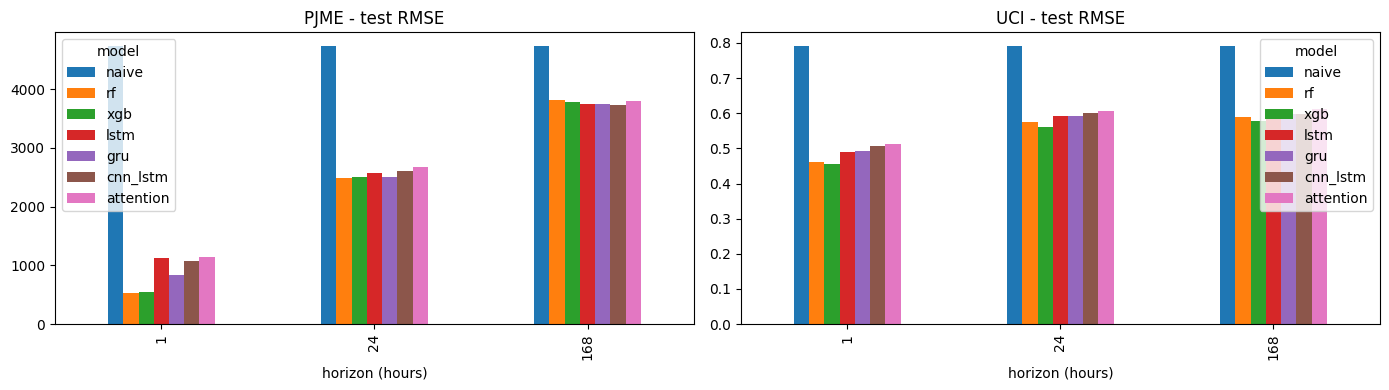

In [11]:
order = ["naive", "rf", "xgb", "lstm", "gru", "cnn_lstm", "attention"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, name in zip(ax, ["pjme", "uci"]):
    # [order] puts the columns (models) in the same order in every chart
    t = both[both["dataset"] == name].groupby(["horizon", "model"])["rmse"].mean().unstack()[order]
    t.plot(kind="bar", ax=a)
    a.set_title(name.upper() + " - test RMSE")
    a.set_xlabel("horizon (hours)")
plt.tight_layout()
plt.savefig("../figures/05_test_rmse.png", dpi=150, bbox_inches="tight")
plt.show()

Notes:
- All models now had the same tuning budget (8 trials at h=24) and the same PJME training data (last 4 years).
- Short horizons: trees are clearly best. PJME 1h RF 532 MW / XGBoost 549 MW vs GRU 829 MW (best deep model).
- PJME 24h: almost a tie. RF 2488, GRU 2509, XGBoost 2512 MW.
- PJME 168h: the deep models are a bit better. CNN-LSTM 3740, LSTM 3747, GRU 3748 vs XGBoost 3780 and RF 3817 MW
  (about 1% difference, check with the DM test in notebook 06).
- UCI: XGBoost is best at all horizons (RMSE 0.457 / 0.562 / 0.578 kW). Best deep models (LSTM / GRU) are
  about 4-7% behind (R2 0.52 vs 0.58 at 1h).
- GRU is the most stable deep model, attention is the weakest deep model everywhere.
- Deep models change more between seeds (PJME RMSE std up to ~160 MW for attention, trees < 9 MW).


In [12]:
# std over the 3 seeds: shows how much the result changes when only the random seed changes
both.groupby(["dataset", "horizon", "model"])["rmse"].std().unstack().round(3)

model            attention  cnn_lstm     gru    lstm  naive     rf    xgb
dataset horizon                                                          
pjme    1          157.199    75.450   9.706  34.850    NaN  4.042  1.029
        24          62.260    59.867   3.209  27.451    NaN  1.827  2.498
        168         52.138    53.736  71.693  51.477    NaN  8.252  4.889
uci     1            0.010     0.011   0.016   0.006    NaN  0.000  0.000
        24           0.007     0.005   0.004   0.002    NaN  0.000  0.000
        168          0.003     0.001   0.007   0.007    NaN  0.001  0.000

##### Attention weights

Mean attention over the test windows, by how many hours before the forecast origin.

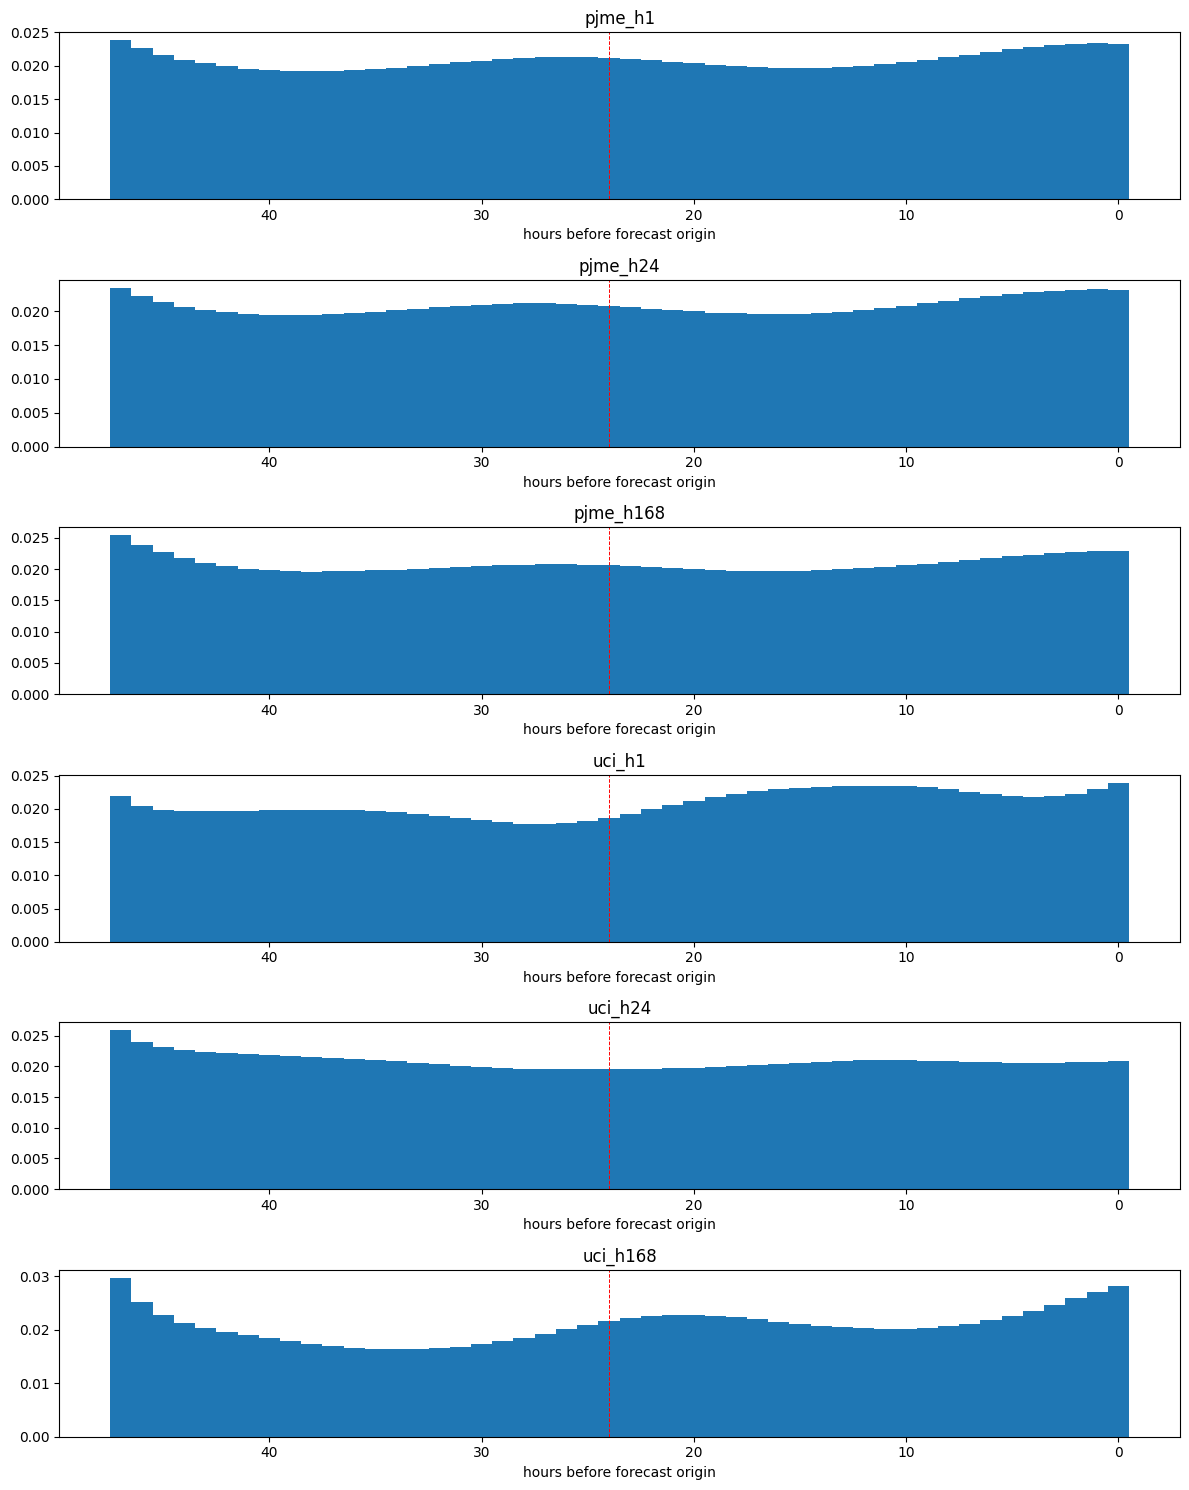

In [13]:
# why: the attention weights should show which past hours the model looks at.
# this is checked against the patterns found in notebook 03
fig, ax = plt.subplots(len(attention), 1, figsize=(12, 2.5 * len(attention)))
# np.atleast_1d() makes sure we can loop over ax even if there is only one chart
for a, (k, w) in zip(np.atleast_1d(ax), attention.items()):
    hours_back = np.arange(len(w))[::-1]
    a.bar(hours_back, w, width=1)
    for lag in [24, 48, 168]:
        if lag < len(w):
            a.axvline(lag, color="red", ls="--", lw=0.7)
    # invert_xaxis() so the oldest hour is on the left and the newest on the right
    a.invert_xaxis()
    a.set_title(k)
    a.set_xlabel("hours before forecast origin")
plt.tight_layout()
plt.savefig("../figures/05_attention_weights.png", dpi=150, bbox_inches="tight")
plt.show()

Notes:
- The attention weights are almost flat: all models use L = 48, so uniform would be 1/48 = 0.021, and the weights
  only go from ~0.016 to ~0.030.
- The largest weights are mostly on the oldest and the newest hours of the window, not on the 24h cycle. With an LSTM
  encoder underneath, each step already carries information from the steps before, so the weights are not a clean
  "which hour matters" measure.
- So for RQ3 the attention weights alone don't show the daily / weekly cycles found in notebook 03.


##### Forecast vs actual - one test week, 24h ahead

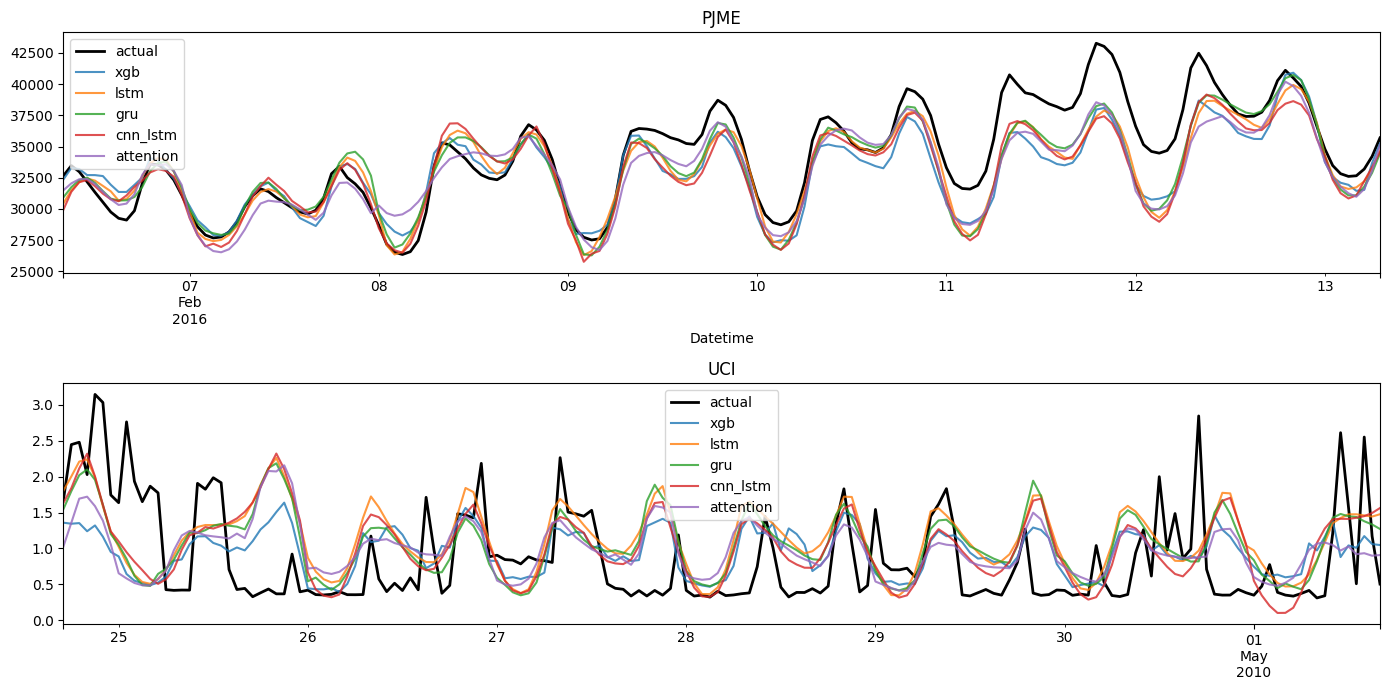

In [14]:
# why: one week of forecasts from all models against the actual load, to see the differences by eye
fig, ax = plt.subplots(2, 1, figsize=(14, 7))
for a, name in zip(ax, ["pjme", "uci"]):
    week = slice(None, 24 * 7)
    first = True
    for model in ["xgb"] + MODELS:
        p = pd.read_parquet(f"../results/predictions/{name}_{model}_h24.parquet")
        if first:
            p["actual"].iloc[week].plot(ax=a, color="black", lw=2, label="actual")
            first = False
        p["seed_0"].iloc[week].plot(ax=a, label=model, alpha=0.8)
    a.set_title(name.upper())
    a.legend()
plt.tight_layout()
plt.savefig("../figures/05_forecast_week_24h.png", dpi=150, bbox_inches="tight")
plt.show()